# 🤖 Álgebra lineal dentro de la IA generativa: el mecanismo de **atención**

**Curso:** Álgebra Lineal &nbsp;|&nbsp; **Modalidad:** en parejas &nbsp;|&nbsp; **Tiempo previsto:** hasta 90 minutos &nbsp;|&nbsp; **Nivel:** intermedio

En esta actividad usarán un **simulador pequeño**, diseñado para aprender, no un modelo de lenguaje real. Sirve para explorar la atención, un mecanismo empleado en los *Transformers*:

| Lo que ven en clase | Dónde aparece en un modelo de lenguaje |
|---|---|
| Vectores en $\mathbb{R}^n$ | Representar cada elemento de una secuencia mediante un vector |
| Transformaciones lineales $T(\mathbf x)=M\mathbf x$ | Construir consultas, claves y valores |
| Producto punto y producto de matrices | Calcular puntajes entre elementos: $QK^T$ |
| Combinaciones lineales | Mezclar valores según los pesos de atención: $AV$ |

🎯 **Pregunta guía:** ¿cómo puede una misma palabra, **banco**, adquirir una representación distinta según su contexto y afectar la predicción de la palabra siguiente?

> **No tienen que programar.** Ustedes mueven controles, toman decisiones basadas en álgebra lineal, hacen algunos cálculos a mano y escriben respuestas en formularios. El código del cuaderno realiza los demás cálculos.

El simulador representa cada **palabra** con dos números escogidos a mano. Los modelos reales usan *tokens* —que no siempre son palabras completas—, vectores de muchas dimensiones y otras operaciones. **Softmax**, por ejemplo, es un paso no lineal; no todo el modelo es una transformación lineal.

## 📋 Antes de empezar: cómo trabajar

1. Abran este archivo **en Google Colab**, no solo en el editor de archivos de su equipo. Guarden una copia con `Archivo → Guardar una copia en Drive` y trabajen en esa copia.
2. Escriban los nombres en el formulario de la Parte 0. Después avancen **de arriba hacia abajo**. Para ejecutar una celda, pulsen el botón ▶️ que aparece a su izquierda.
3. En cada parte sigan este ciclo: **lean → exploren → calculen o decidan → completen el formulario → pulsen ▶️ para revisar**.

| Símbolo | Qué es | Qué hacen ustedes |
|---|---|---|
| ▶️ **Ejecutar** | Configuración o resultado preparado | Pulsen ▶️. No cambien el código. |
| 🔍 **Explorador** | Menús y deslizadores con gráficos | Pulsen ▶️; después muevan los controles y lean el resultado. |
| ✍️ **Respuestas** | Campos y menús de un formulario | Completen los campos y pulsen ▶️. Si cambian una respuesta, pulsen ▶️ de nuevo. |

**En pareja:** una persona propone y explica; la otra manipula el explorador y registra. Intercambien los roles en la parte siguiente. Ambos deben estar de acuerdo antes de responder.

**Cómo llenar y revisar:**
- Escriban los números con punto o coma decimal (`0.36` o `0,36`) o como fracción (`1/3`). Para un conteo grande escriban el entero sin separadores, por ejemplo `589824`. Redondeen a dos decimales solo cuando se indique.
- En las matrices, cada campo indica su fila y columna. Por ejemplo, para $\begin{bmatrix}7&8\\9&10\end{bmatrix}$: fila 1/columna 1 = `7`, fila 1/columna 2 = `8`, fila 2/columna 1 = `9`, fila 2/columna 2 = `10`.
- ✅ significa **correcta**; ❌, **incorrecta** y muestra una pista; ⏳, **faltan campos**. Pueden corregir y volver a revisar. Una pregunta con varios campos se revisa como un conjunto: completen todos.
- Las dos respuestas 📝 se registran en la sesión al ejecutar su formulario, pero **las califica el docente**, no el computador. Guarden la copia en Drive para conservar los valores de sus campos.
- Si ven código, no lo editen: en Colab pueden usar `Ver → Mostrar/ocultar código` o el botón de la celda. Si no aparecen los controles, ejecuten primero la configuración y después el explorador correspondiente.

**Al terminar:** ejecuten 📊 **Resumen**, verifiquen nombres y estados, guarden la copia y descarguen el archivo con `Archivo → Descargar → Descargar .ipynb`. Entreguen ese archivo por el medio indicado por su docente.

**Si Colab se desconecta o reinicia:** ejecuten otra vez la configuración y cada formulario que ya habían completado; revisen que sus campos sigan llenos, repongan los que falten y ejecuten el resumen. Este refleja la **última ejecución**, no cambios que todavía no hayan revisado.

### ⏱️ Tiempo previsto y evaluación

| Parte | Tema | Tiempo | Puntos |
|---|---|---|---|
| 0 | Preparación e instrucciones | 5 min | — |
| 1 | Vectores y producto punto | 9 min | 8 |
| 2 | Transformaciones lineales | 15 min | 20 |
| 3 | Consultas y dimensiones de matrices | 10 min | 8 |
| 4 | Puntajes y softmax | 7 min | 5 |
| 5 | Combinación lineal de valores | 9 min | 10 |
| 6 | Diseñar una transformación | 15 min | 20 |
| 7 | Máscara y siguiente palabra | 12 min | 15 |
| 8 | Escala y reflexión | 8 min | 14 |
| | **Total** | **90 min** | **100**: 80 automáticos y 20 del docente |

---
## Parte 0 · Preparación (5 min)

**Paso 1.** Lean las instrucciones y guarden una copia en Drive. **Paso 2.** ▶️ Ejecuten la celda de configuración. No necesitan leer su contenido. Deben ver **✅ Todo listo**.

In [1]:
# @title ▶️ Ejecutar: configuración (no modificar) { display-mode: "form" }
import base64, json, unicodedata
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patheffects
import ipywidgets as widgets
from ipywidgets import interact
from IPython.display import display

np.set_printoptions(precision=2, suppress=True)
plt.rcParams["figure.dpi"] = 90

# ---------- Modelo de juguete ----------
# Cada palabra es un vector de R^2: (finanzas, naturaleza)
emb = {"dinero":   np.array([1.0, 0.0]),
       "presta":   np.array([0.9, 0.2]),
       "banco":    np.array([0.5, 0.5]),
       "río":      np.array([0.0, 1.0]),
       "pescamos": np.array([0.2, 0.9])}
PALABRAS = list(emb)
COLOR = {"dinero": "tab:green", "presta": "tab:olive", "banco": "tab:purple",
         "río": "tab:blue", "pescamos": "tab:cyan"}
CANDIDATAS = ["intereses", "créditos", "peces", "agua"]
E_sal = np.array([[3.0, 0.0], [2.0, 1.0], [0.0, 3.0], [1.0, 2.0]])
I2 = np.eye(2)

def softmax(v):
    v = np.asarray(v, dtype=float)
    e = np.exp(v - v.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)

def atencion(frase, W_Q=I2, W_K=I2, W_V=I2, causal=False):
    X = np.array([emb[w] for w in frase])
    Q, K, V = X @ W_Q.T, X @ W_K.T, X @ W_V.T          # q_i = W_Q x_i (filas)
    S = Q @ K.T / np.sqrt(2)                            # d_k = 2
    if causal:
        S = np.where(np.tril(np.ones_like(S)) == 1, S, -np.inf)
    A = softmax(S)
    return {"X": X, "Q": Q, "K": K, "V": V, "S": S, "A": A, "Z": A @ V}

def predecir(frase):
    z = atencion(frase, causal=True)["Z"][-1]
    logits = E_sal @ z
    return z, logits, softmax(logits)

# ---------- Gráficas ----------
def _mapa(ax, M, filas, cols, titulo, fmt="{:.2f}", cmap="viridis", vmin=None, vmax=None):
    Mm = np.where(np.isfinite(M), M, np.nan)
    ax.imshow(Mm, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols)
    ax.set_yticks(range(len(filas))); ax.set_yticklabels(filas)
    ax.set_title(titulo)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            txt = "−∞" if not np.isfinite(M[i, j]) else fmt.format(M[i, j])
            ax.text(j, i, txt, ha="center", va="center", color="white",
                    fontsize=11, fontweight="bold",
                    path_effects=[patheffects.withStroke(linewidth=2, foreground="black")])

def _plano(ax, lim=1.3):
    ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel("finanzas"); ax.set_ylabel("naturaleza"); ax.grid(alpha=0.3)

def _flecha(ax, v, color, etiqueta, alpha=1.0, lw=2):
    ax.annotate("", xy=v, xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=color, lw=lw, alpha=alpha))
    ax.text(v[0] * 1.06, v[1] * 1.06 + 0.03, etiqueta, color=color, alpha=alpha, fontsize=10)

def _matriz_txt(M):
    M = np.asarray(M, dtype=float)
    return "\n".join("   [ " + "  ".join(f"{x:6.2f}" for x in fila) + " ]" for fila in M)

# ---------- Revisión de respuestas ----------
_P = json.loads(base64.b64decode("eyIxLjEiOiBbImV4YWN0byIsIFswLjM2XSwgNCwgIk11bHRpcGxpcXVlbiBsYXMgcHJpbWVyYXMgY29tcG9uZW50ZXMgeSBsYXMgc2VndW5kYXM7IGRlc3B1w6lzIHN1bWVuLiJdLCAiMS4yIjogWyJvcCIsICIoMiwzKSB5ICgzLDIpIiwgNCwgIkJ1c3F1ZW4gbGEgZmlsYSBkZSBiYW5jbyB5IGxhIGNvbHVtbmEgZGUgcsOtbzsgbHVlZ28gaW50ZXJjYW1iaWVuIGZpbGEgeSBjb2x1bW5hLiJdLCAiMi4xIjogWyJleGFjdG8iLCBbMCwgMSwgMSwgMF0sIDQsICJMYSBwcmltZXJhIGNvbHVtbmEgZXMgbGEgaW1hZ2VuIGRlIGXigoEgeSBsYSBzZWd1bmRhIGVzIGxhIGltYWdlbiBkZSBl4oKCLiJdLCAiMi4yIjogWyJleGFjdG8iLCBbMSwgMCwgMCwgMF0sIDQsICJMYSBwcmltZXJhIGNvbXBvbmVudGUgc2UgY29uc2VydmEgeSBsYSBzZWd1bmRhIHNlIHZ1ZWx2ZSBjZXJvLiJdLCAiMi4zIjogWyJvcCIsICJObzogZG9zIHZlY3RvcmVzIGRpc3RpbnRvcyBwdWVkZW4gdGVuZXIgbGEgbWlzbWEgaW1hZ2VuIiwgNCwgIkNvbXBhcmVuIGxhcyBpbcOhZ2VuZXMgZGUgKDAuNSwgMC41KSB5ICgwLjUsIDApLiJdLCAiMi40IjogWyJleGFjdG8iLCBbMiwgMCwgMSwgMywgMSwgMl0sIDgsICJMYXMgaW3DoWdlbmVzIGRlIGXigoEgeSBl4oKCIHNvbiBsYXMgY29sdW1uYXMgZGUgTTsgZGVzcHXDqXMgY2FsY3VsZW4gTcK3KDAuNSwgMC41KS4iXSwgIjMuMSI6IFsiZXhhY3RvIiwgWzAuNSwgMS41XSwgMywgIk11bHRpcGxpcXVlbiBXX1EgcG9yIGVsIHZlY3RvciBjb2x1bW5hIGRlIGJhbmNvOiAoMC41LCAwLjUpLiJdLCAiMy4yIjogWyJleGFjdG8iLCBbNSwgMywgNSwgNV0sIDUsICJRID0gKDXDlzQpKDTDlzMpOyBLIHRpZW5lIGVsIG1pc21vIHRhbWHDsW8gcXVlIFEuIl0sICI0LjEiOiBbIm9wIiwgIkNvbiAoMSwgMC41LCAwKSBhdW1lbnRhIGVsIHBlc28gZGVsIG1heW9yOyBjb24gcHVudGFqZXMgaWd1YWxlcyBsb3MgcGVzb3Mgc2lndWVuIGlndWFsZXMiLCA1LCAiQ29tcGFyZW4gbG9zIGRvcyBleHBlcmltZW50b3MgdXNhbmRvIG11bHRpcGxpY2Fkb3JlcyAxIHkgMTAuIl0sICI1LjEiOiBbImRlY2ltYWwiLCBbMC4yMywgMC44XSwgNiwgIk11bHRpcGxpcXVlbiBjYWRhIHZlY3RvciBwb3IgZWwgcGVzbyBkZSBsYSBmaWxhIGJhbmNvIHkgc3VtZW4gY29tcG9uZW50ZSBhIGNvbXBvbmVudGUuIl0sICI1LjIiOiBbIm9wIiwgIkVzIHVuYSBjb21iaW5hY2nDs24gY29uIHBlc29zIG5vIG5lZ2F0aXZvcyBxdWUgc3VtYW4gMSIsIDQsICJSZXZpc2VuIGxhcyBkb3MgcHJvcGllZGFkZXMgZGUgbG9zIHBlc29zIGRlIHVuYSBmaWxhIGRlIEEuIl0sICI2LjEiOiBbInJldG8iLCAicmlvIiwgNSwgIlBydWViZW4gdW5hIGNvbnN1bHRhIHEgY3V5byBwcm9kdWN0byBwdW50byBjb24gcsOtbyBzZWEgc3VmaWNpZW50ZW1lbnRlIG1heW9yIHF1ZSBjb24gbGFzIG90cmFzIGRvcyBwYWxhYnJhcy4iXSwgIjYuMiI6IFsicmV0byIsICJkaW5lcm8iLCA1LCAiUHJ1ZWJlbiB1bmEgY29uc3VsdGEgcSBjdXlvIHByb2R1Y3RvIHB1bnRvIGNvbiBkaW5lcm8gc2VhIHN1ZmljaWVudGVtZW50ZSBtYXlvciBxdWUgY29uIGxhcyBvdHJhcyBkb3MgcGFsYWJyYXMuIl0sICI2LjMiOiBbInR4dCIsIG51bGwsIDEwLCAiIl0sICI3LjEiOiBbIm9wIiwgIlRyaWFuZ3VsYXIgaW5mZXJpb3IiLCA1LCAiQ29uIGxhIG3DoXNjYXJhLCBsb3MgcGVzb3MgaGFjaWEgcGFsYWJyYXMgcG9zdGVyaW9yZXMgc29uIGNlcm8uIl0sICI3LjIiOiBbImV4YWN0byIsIFsyLjRdLCA1LCAiTGEgZmlsYSBkZSBwZWNlcyBlcyAoMCwgMyk7IG11bHRpcGzDrXF1ZW5sYSBwb3IgKDAuMiwgMC44KS4iXSwgIjcuMyI6IFsicmV0byIsICJkb3NfY29udGV4dG9zIiwgNSwgIlBydWViZW4gcGFsYWJyYXMgZGUgbmF0dXJhbGV6YSBwYXJhIHBlY2VzIHkgZGUgZmluYW56YXMgcGFyYSBpbnRlcmVzZXM7IGNvbXBydWViZW4gcXVlIG5vIGhheWEgZW1wYXRlLiJdLCAiOC4xIjogWyJleGFjdG8iLCBbMTA0ODU3Nl0sIDQsICJMYSBtYXRyaXogdGllbmUgMTAyNCBmaWxhcyB5IDEwMjQgY29sdW1uYXMuIE11bHRpcGxpcXVlbiB5IGVzY3JpYmFuIGVsIGVudGVybyBzaW4gc2VwYXJhZG9yZXMuIl0sICI4LjIiOiBbInR4dCIsIG51bGwsIDEwLCAiIl19").decode())
_VERSION_ACTIVIDAD = "atencion-interactiva-revisada-1"
if (globals().get("_version_progreso") != _VERSION_ACTIVIDAD
        or "_progreso" not in globals() or "_abiertas" not in globals()):
    _progreso, _abiertas = {}, {}
    _version_progreso = _VERSION_ACTIVIDAD
SEL = "(seleccionen)"

def _norm(s):
    s = unicodedata.normalize("NFD", str(s)).encode("ascii", "ignore").decode()
    return " ".join(s.lower().split())

def _num(s):
    s = str(s).strip().replace(" ", "").replace("−", "-")
    if s.count(",") == 1 and "." not in s:
        s = s.replace(",", ".")
    try:
        numero = float(Fraction(s))
    except (ValueError, ZeroDivisionError, OverflowError):
        raise ValueError("Escriban un número válido, por ejemplo 0.5, 0,5 o 1/2.") from None
    if not np.isfinite(numero):
        raise ValueError("Escriban un número finito.")
    return numero

def _reto(clave, valores):
    if clave in ("rio", "dinero"):
        W = np.array([_num(v) for v in valores]).reshape(2, 2)
        try:
            with np.errstate(over="raise", invalid="raise", divide="raise"):
                A = atencion(["dinero", "banco", "río"], W_Q=W)["A"]
        except FloatingPointError:
            raise ValueError("Las entradas son demasiado grandes; prueben valores entre −4 y 4.") from None
        peso = A[1, 2] if clave == "rio" else A[1, 0]
        destino = "río" if clave == "rio" else "dinero"
        return peso > 0.5, f"Banco da {peso:.3%} a {destino}; se necesita estrictamente más de 50%."
    if clave != "dos_contextos" or len(valores) != 4:
        raise ValueError("No se pudo interpretar el reto; pidan ayuda al docente.")
    resultados = []
    detalles = []
    for palabras, objetivo in ((valores[:2], "peces"), (valores[2:], "intereses")):
        if any(palabra not in emb for palabra in palabras):
            raise ValueError("Elijan las palabras de los menús del formulario.")
        frase = list(palabras) + ["banco"]
        _, _, probs = predecir(frase)
        indice = CANDIDATAS.index(objetivo)
        mejor_otra = np.max(np.delete(probs, indice))
        logrado = probs[indice] > mejor_otra + 1e-10
        resultados.append(logrado)
        detalles.append(f"{' '.join(frase)}: {objetivo} = {probs[indice]:.3f}, mejor alternativa = {mejor_otra:.3f}")
    return all(resultados), "; ".join(detalles) + "."

def _revisar(qid, *valores):
    tipo, resp, pts, pista = _P[qid]
    if any(str(v).strip() in ("", SEL) for v in valores):
        _progreso[qid] = "pendiente"
        _abiertas.pop(qid, None)
        print(f"⏳ {qid}: pendiente (hay un campo vacío o sin seleccionar).")
        return
    if tipo == "txt":
        _abiertas[qid] = str(valores[0]).strip()
        _progreso[qid] = "manual"
        print(f"📝 {qid}: registrada en esta sesión; la califica el docente.")
        return
    detalle = ""
    try:
        if tipo == "op":
            ok = _norm(valores[0]) == _norm(resp)
        elif tipo in ("exacto", "decimal"):
            if len(valores) != len(resp):
                raise RuntimeError(f"El formulario {qid} tiene un número incorrecto de campos.")
            nums = [_num(v) for v in valores]
            if tipo == "exacto":
                errores = [i + 1 for i, (a, b) in enumerate(zip(nums, resp)) if a != b]
            else:
                errores = [i + 1 for i, (a, b) in enumerate(zip(nums, resp))
                           if abs(a - b) > 0.005 + 1e-12]
            ok = not errores
            if errores and len(valores) > 1:
                detalle = "Revisen los campos " + ", ".join(map(str, errores)) + " en el orden del formulario."
        elif tipo == "reto":
            ok, detalle = _reto(resp, valores)
        else:
            raise RuntimeError(f"Tipo de pregunta desconocido: {tipo}")
    except ValueError as error:
        _progreso[qid] = "incorrecta"
        print(f"❌ {qid}: {error}")
        return
    _progreso[qid] = "correcta" if ok else "incorrecta"
    if ok:
        print(f"✅ {qid}: correcta (+{pts} pts). {detalle}")
    else:
        print(f"❌ {qid}: incorrecta. {detalle}\n   💡 Pista: {pista}")

print("✅ Todo listo. Pueden continuar.")

✅ Todo listo. Pueden continuar.


**Paso 3.** Escriban ambos nombres en el formulario y pulsen ▶️. Comprueben que aparezcan debajo.

In [2]:
# @title ✍️ Integrantes de la pareja { display-mode: "form" }
estudiante_1 = ""  # @param {type:"string"}
estudiante_2 = ""  # @param {type:"string"}
print("Pareja:", estudiante_1 or "(sin nombre)", "y", estudiante_2 or "(sin nombre)")

Pareja: (sin nombre) y (sin nombre)


---
## Parte 1 · Palabras como vectores y producto punto (9 min · 8 pts)

En este simulador representamos cada palabra con un vector de $\mathbb{R}^2$. Inventamos las coordenadas **(finanzas, naturaleza)** para poder dibujarlas; no interpreten estos valores como vectores reales de un Transformer.

| Palabra | Vector |
|---|---|
| dinero | $(1.0,\ 0.0)$ |
| presta | $(0.9,\ 0.2)$ |
| banco | $(0.5,\ 0.5)$ ← ¡ambigua! |
| río | $(0.0,\ 1.0)$ |
| pescamos | $(0.2,\ 0.9)$ |

El **producto punto** es $\mathbf u\cdot\mathbf v = u_1v_1 + u_2v_2$. En este ejemplo lo usamos como puntaje de compatibilidad. Depende tanto de la dirección como de la longitud de los vectores; por sí solo no demuestra que dos palabras estén relacionadas.

🔍 **Explorador 1.** Primero calculen a mano el producto de **presta** y **pescamos**. Después ejecuten la celda, seleccionen esas dos palabras y comparen con el resultado. Cambien una de ellas por **río** y observen cómo cambia el puntaje.

In [3]:
# @title 🔍 Explorador 1: producto punto entre palabras { display-mode: "form" }
def _explorador_1(palabra_1, palabra_2):
    u, v = emb[palabra_1], emb[palabra_2]
    fig, ax = plt.subplots(figsize=(5, 5))
    _plano(ax)
    for w in PALABRAS:
        if w not in (palabra_1, palabra_2):
            _flecha(ax, emb[w], COLOR[w], w, alpha=0.25)
    _flecha(ax, u, COLOR[palabra_1], palabra_1, lw=3)
    _flecha(ax, v, COLOR[palabra_2], palabra_2, lw=3)
    ax.set_title(f"{palabra_1} · {palabra_2} = {u @ v:.2f}")
    plt.show()
    plt.close(fig)
    print(f"{palabra_1} = {tuple(u)}   {palabra_2} = {tuple(v)}")
    print(f"{palabra_1} · {palabra_2} = ({u[0]})({v[0]}) + ({u[1]})({v[1]}) = {u @ v:.2f}")

interact(_explorador_1,
         palabra_1=widgets.Dropdown(options=PALABRAS, value="pescamos", description="Palabra 1"),
         palabra_2=widgets.Dropdown(options=PALABRAS, value="dinero", description="Palabra 2"));

interactive(children=(Dropdown(description='Palabra 1', index=4, options=('dinero', 'presta', 'banco', 'río', …

En este primer ejemplo ponemos los vectores como **filas** de una matriz $X$. El producto $XX^T$ reúne todas las comparaciones. Más adelante usaremos matrices distintas de consultas y claves, como en la atención:

$$S = X X^T, \qquad S_{ij} = (\text{palabra } i)\cdot(\text{palabra } j).$$

▶️ Ejecuten la celda para ver $X$ y $S = XX^T$ para la frase **"pescamos banco río"**.

X (una fila por palabra; columnas = finanzas, naturaleza):
   [   0.20    0.90 ]
   [   0.50    0.50 ]
   [   0.00    1.00 ]


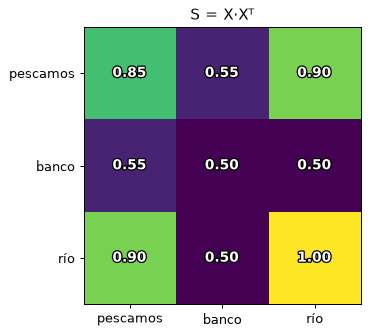

In [4]:
# @title ▶️ Ejecutar: matriz de similitudes S = X·Xᵀ { display-mode: "form" }
_frase = ["pescamos", "banco", "río"]
_X = np.array([emb[w] for w in _frase])
print("X (una fila por palabra; columnas = finanzas, naturaleza):")
print(_matriz_txt(_X))
fig, ax = plt.subplots(figsize=(4, 4))
_mapa(ax, _X @ _X.T, _frase, _frase, "S = X·Xᵀ")
plt.show()
plt.close(fig)

### Qué deben responder
1. **1.1** Escriban el resultado que calcularon para $\text{presta}\cdot\text{pescamos}$.
2. **1.2** En $S = XX^T$ para «pescamos banco río», numeren filas y columnas desde 1. Seleccionen las dos posiciones donde aparece $\text{banco}\cdot\text{río}$.
3. Pulsen ▶️ en el formulario para revisar las dos respuestas.

In [5]:
# @title ✍️ Respuestas Parte 1 { display-mode: "form", single-column: true }
# @markdown **1.1** presta · pescamos =
r1_1_producto = ""  # @param {type:"string"}
# @markdown **1.2** Posiciones de banco·río en S:
r1_2_posiciones = "(seleccionen)"  # @param ["(seleccionen)", "(1,2) y (2,1)", "(2,3) y (3,2)", "solo (2,3)", "(3,3)"]
# @markdown ---
# @markdown 👉 **Pulsen ▶️ para revisar. Si cambian una respuesta, pulsen ▶️ otra vez.**
if "_revisar" not in globals():
    print("⚠️ Primero ejecuten la celda de configuración de la Parte 0.")
else:
    _revisar("1.1", r1_1_producto)
    _revisar("1.2", r1_2_posiciones)

⏳ 1.1: pendiente (hay un campo vacío o sin seleccionar).
⏳ 1.2: pendiente (hay un campo vacío o sin seleccionar).


---
## Parte 2 · Transformaciones lineales del plano (15 min · 20 pts)

Antes de comparar palabras, un Transformer las **transforma** con matrices: $T(\mathbf x) = M\mathbf x$. Recuerden:

$$M = \begin{bmatrix} a & b \\ c & d \end{bmatrix}, \qquad M\mathbf e_1 = \begin{bmatrix} a \\ c \end{bmatrix}\ (\text{1ª columna}), \qquad M\mathbf e_2 = \begin{bmatrix} b \\ d \end{bmatrix}\ (\text{2ª columna}).$$

🔍 **Explorador 2.** Muevan los cuatro deslizadores $a, b, c, d$. Verán:
- **Izquierda:** la cuadrícula transformada y las imágenes de $\mathbf e_1$ (rojo) y $\mathbf e_2$ (azul).
- **Derecha:** las palabras **antes** (claras) y **después** (fuertes). El triángulo negro representa un vector auxiliar $\mathbf u=(0.5,0)$, que no es una palabra.
- **Abajo:** el determinante, las imágenes de banco y $\mathbf u$, y el estado de los dos retos.

Los ejes de las gráficas se ajustan automáticamente para que quepan las imágenes. Comparen también las coordenadas; no se guíen solo por el tamaño aparente.

| Reto | Qué deben lograr |
|---|---|
| **A · Intercambio** | Que el vector de cada palabra intercambie sus coordenadas: dinero $(1,0)$ ↦ $(0,1)$ y río $(0,1)$ ↦ $(1,0)$. |
| **B · Proyección** | Que cada palabra conserve su coordenada "finanzas" y pierda la de "naturaleza": $(x, y) \mapsto (x, 0)$. |

**Pasos:** busquen una matriz que logre A y copien sus cuatro entradas en 2.1. Después busquen una matriz que logre B y copien sus entradas en 2.2. Para cada reto observen la imagen de $\mathbf e_1$ y la de $\mathbf e_2$.

In [6]:
# @title 🔍 Explorador 2: transformaciones lineales { display-mode: "form" }
def _explorador_2(a, b, c, d):
    M = np.array([[a, b], [c, d]])
    u = np.array([0.5, 0.0])
    cuad = M @ np.array([[0, 1, 1, 0, 0], [0, 0, 1, 1, 0]])
    imagenes = M @ np.array(list(emb.values()) + [u]).T
    lim = max(1.3, 1.2 * np.max(np.abs(cuad)), 1.2 * np.max(np.abs(imagenes)))
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    ax = axs[0]; _plano(ax, lim=lim)
    for t in np.linspace(-2, 2, 9):
        l1 = M @ np.array([np.linspace(-2, 2, 2), [t, t]])
        l2 = M @ np.array([[t, t], np.linspace(-2, 2, 2)])
        ax.plot(*l1, color="gray", lw=0.6, alpha=0.6); ax.plot(*l2, color="gray", lw=0.6, alpha=0.6)
    ax.fill(*cuad, color="gold", alpha=0.35)
    _flecha(ax, M[:, 0], "red", "M·e₁", lw=3); _flecha(ax, M[:, 1], "blue", "M·e₂", lw=3)
    ax.set_title("Cuadrícula y cuadrado unitario transformados")
    ax = axs[1]; _plano(ax, lim=lim)
    for w in PALABRAS:
        x = emb[w]; y = M @ x
        ax.scatter(*x, color=COLOR[w], alpha=0.25, s=60)
        ax.scatter(*y, color=COLOR[w], s=90, edgecolor="black")
        ax.annotate("", xy=y, xytext=x, arrowprops=dict(arrowstyle="->", color=COLOR[w], alpha=0.5))
        ax.text(y[0] + 0.05, y[1] + 0.05, w, color=COLOR[w])
    ax.scatter(*u, marker="^", color="black", alpha=0.25, s=70)
    ax.scatter(*(M @ u), marker="^", color="black", s=70, zorder=5)
    ax.set_title("Palabras y vector auxiliar: antes → después")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    print("M =\n" + _matriz_txt(M))
    det = float(np.linalg.det(M))
    print(f"det(M) = {det:.2f}; área del cuadrado transformado = |det(M)| = {abs(det):.2f}")
    print(f"banco → {tuple(np.round(M @ emb['banco'], 2))}; u = (0.5, 0) → {tuple(np.round(M @ u, 2))}")
    ok_a = np.allclose(M, [[0, 1], [1, 0]])
    ok_b = np.allclose(M, [[1, 0], [0, 0]])
    print("Reto A · Intercambio:", "✅ ¡logrado! Copien esta matriz en el formulario." if ok_a else "⬜ aún no")
    print("Reto B · Proyección: ", "✅ ¡logrado! Copien esta matriz en el formulario." if ok_b else "⬜ aún no")

_s = dict(min=-3, max=3, step=0.5, continuous_update=False)
interact(_explorador_2,
         a=widgets.FloatSlider(value=1, description="a", **_s),
         b=widgets.FloatSlider(value=0, description="b", **_s),
         c=widgets.FloatSlider(value=0, description="c", **_s),
         d=widgets.FloatSlider(value=1, description="d", **_s));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='a', max=3.0, min=-3.0, step…

### Qué deben responder
- **2.1 y 2.2:** registren las matrices de los retos A y B, respectivamente.
- **2.3:** con la proyección B, ¿puede recuperarse **cualquier vector original de $\mathbb R^2$** a partir de su imagen? Comparen las imágenes de banco $(0.5,0.5)$ y del vector auxiliar $\mathbf u=(0.5,0)$. No limiten la pregunta a las cinco palabras de la tabla.
- **2.4:** si $T(\mathbf e_1)=(2,1)$ y $T(\mathbf e_2)=(0,3)$, escriban la matriz de $T$ y calculen $T(\text{banco})$ usando $\text{banco}=0.5\mathbf e_1+0.5\mathbf e_2$. Para comprobar la matriz, pongan sus cuatro entradas en el Explorador 2; el deslizador puede llegar a 3.

Cada matriz se llena por filas: primero fila 1/columna 1 y fila 1/columna 2; después fila 2/columna 1 y fila 2/columna 2.

In [7]:
# @title ✍️ Respuestas Parte 2 { display-mode: "form", single-column: true }
# @markdown **2.1** Matriz del Reto A:
# @markdown **Fila 1, columna 1**:
a_f1c1 = ""  # @param {type:"string"}
# @markdown **Fila 1, columna 2**:
a_f1c2 = ""  # @param {type:"string"}
# @markdown **Fila 2, columna 1**:
a_f2c1 = ""  # @param {type:"string"}
# @markdown **Fila 2, columna 2**:
a_f2c2 = ""  # @param {type:"string"}
# @markdown **2.2** Matriz del Reto B:
# @markdown **Fila 1, columna 1**:
b_f1c1 = ""  # @param {type:"string"}
# @markdown **Fila 1, columna 2**:
b_f1c2 = ""  # @param {type:"string"}
# @markdown **Fila 2, columna 1**:
b_f2c1 = ""  # @param {type:"string"}
# @markdown **Fila 2, columna 2**:
b_f2c2 = ""  # @param {type:"string"}
# @markdown **2.3** Con B, ¿se puede recuperar cualquier vector de R² a partir de su imagen?
r2_3 = "(seleccionen)"  # @param ["(seleccionen)", "Sí: todas las transformaciones lineales son invertibles", "No: dos vectores distintos pueden tener la misma imagen", "Sí: el determinante es 1", "No: toda matriz simétrica pierde información"]
# @markdown **2.4** Escriban la matriz de T y las dos componentes de T(banco):
# @markdown **Fila 1, columna 1**:
t_f1c1 = ""  # @param {type:"string"}
# @markdown **Fila 1, columna 2**:
t_f1c2 = ""  # @param {type:"string"}
# @markdown **Fila 2, columna 1**:
t_f2c1 = ""  # @param {type:"string"}
# @markdown **Fila 2, columna 2**:
t_f2c2 = ""  # @param {type:"string"}
# @markdown **T(banco), primera componente**:
t_banco_primera = ""  # @param {type:"string"}
# @markdown **T(banco), segunda componente**:
t_banco_segunda = ""  # @param {type:"string"}
# @markdown ---
# @markdown 👉 **Pulsen ▶️ para revisar. Si cambian una respuesta, pulsen ▶️ otra vez.**
if "_revisar" not in globals():
    print("⚠️ Primero ejecuten la celda de configuración de la Parte 0.")
else:
    _revisar("2.1", a_f1c1, a_f1c2, a_f2c1, a_f2c2)
    _revisar("2.2", b_f1c1, b_f1c2, b_f2c1, b_f2c2)
    _revisar("2.3", r2_3)
    _revisar("2.4", t_f1c1, t_f1c2, t_f2c1, t_f2c2, t_banco_primera, t_banco_segunda)

⏳ 2.1: pendiente (hay un campo vacío o sin seleccionar).
⏳ 2.2: pendiente (hay un campo vacío o sin seleccionar).
⏳ 2.3: pendiente (hay un campo vacío o sin seleccionar).
⏳ 2.4: pendiente (hay un campo vacío o sin seleccionar).


💡 **Conexión con la IA:** en un Transformer, las matrices de transformación **no se escriben a mano**: se **aprenden** con millones de ejemplos. Pero su efecto es el mismo que vieron: rotar, estirar, proyectar y mezclar las coordenadas de cada palabra para resaltar la información útil.

---
## Parte 3 · Consultas y claves: producto de matrices (10 min · 8 pts)

La atención transforma cada palabra $\mathbf x_i$ con **tres** matrices distintas:

| Vector | Fórmula | Interpretación |
|---|---|---|
| **Consulta** (*query*) | $\mathbf q_i = W_Q\,\mathbf x_i$ | "¿Qué información busco?" |
| **Clave** (*key*) | $\mathbf k_i = W_K\,\mathbf x_i$ | "¿Qué información ofrezco?" |
| **Valor** (*value*) | $\mathbf v_i = W_V\,\mathbf x_i$ | "Lo que entrego si me prestan atención" |

Como las palabras son las **filas** de $X$, todas las consultas se calculan de una vez con un producto de matrices:

$$Q = X\,W_Q^{T} \quad(\text{la fila } i \text{ de } Q \text{ es } \mathbf q_i^T), \qquad K = X\,W_K^{T}, \qquad V = X\,W_V^{T}.$$

Después, el producto punto $\mathbf q_i\cdot\mathbf k_j$ da el puntaje **sin escalar** de la palabra $i$ hacia la $j$. La atención usa el puntaje escalado $(\mathbf q_i\cdot\mathbf k_j)/\sqrt{d_k}$; todos se obtienen con $\dfrac{QK^T}{\sqrt{d_k}}$, donde $d_k$ es la dimensión de las consultas (aquí $d_k=2$).

▶️ Ejecuten la celda para ver un ejemplo con $W_Q = \begin{bmatrix}1&0\\0&3\end{bmatrix}$ y $W_K = I$.

W_Q =
   [   1.00    0.00 ]
   [   0.00    3.00 ]

X (filas: pescamos, banco, río) =
   [   0.20    0.90 ]
   [   0.50    0.50 ]
   [   0.00    1.00 ]

Q = X·W_Qᵀ =
   [   0.20    2.70 ]
   [   0.50    1.50 ]
   [   0.00    3.00 ]


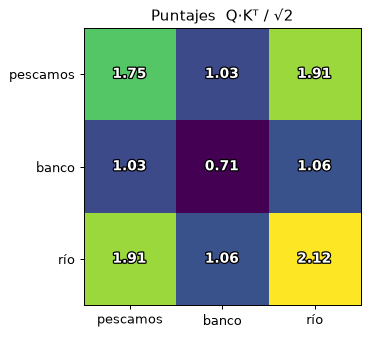

In [8]:
# @title ▶️ Ejecutar: ejemplo de Q = X·W_Qᵀ y de los puntajes { display-mode: "form" }
_frase = ["pescamos", "banco", "río"]
_WQ = np.array([[1.0, 0.0], [0.0, 3.0]])
_r = atencion(_frase, W_Q=_WQ)
print("W_Q =\n" + _matriz_txt(_WQ))
print("\nX (filas: pescamos, banco, río) =\n" + _matriz_txt(_r["X"]))
print("\nQ = X·W_Qᵀ =\n" + _matriz_txt(_r["Q"]))
fig, ax = plt.subplots(figsize=(4, 4))
_mapa(ax, _r["S"], _frase, _frase, "Puntajes  Q·Kᵀ / √2")
plt.show()
plt.close(fig)

### Qué deben responder
- **3.1** Con $W_Q=\begin{bmatrix}1&0\\0&3\end{bmatrix}$, calculen a mano $\mathbf q_{\text{banco}}=W_Q\,\text{banco}$. Comparen sus dos componentes con la fila 2 de $Q$ de arriba.
- **3.2** Para otra secuencia de **5 palabras**, supongan que $X$ es $5\times4$ y que $W_Q$ y $W_K$ son $3\times4$. Registren las filas y columnas de $Q=XW_Q^T$ y de $QK^T$.

Recuerden: en $(a\times b)(b\times c)$ coinciden las dimensiones interiores $b$ y el resultado es $a\times c$.

In [9]:
# @title ✍️ Respuestas Parte 3 { display-mode: "form", single-column: true }
# @markdown **3.1** Componentes de q_banco:
# @markdown **Primera componente**:
q_banco_primera = ""  # @param {type:"string"}
# @markdown **Segunda componente**:
q_banco_segunda = ""  # @param {type:"string"}
# @markdown **3.2** Dimensiones de Q y Q·Kᵀ:
# @markdown **Filas de Q**:
filas_q = ""  # @param {type:"string"}
# @markdown **Columnas de Q**:
columnas_q = ""  # @param {type:"string"}
# @markdown **Filas de Q·Kᵀ**:
filas_qkt = ""  # @param {type:"string"}
# @markdown **Columnas de Q·Kᵀ**:
columnas_qkt = ""  # @param {type:"string"}
# @markdown ---
# @markdown 👉 **Pulsen ▶️ para revisar. Si cambian una respuesta, pulsen ▶️ otra vez.**
if "_revisar" not in globals():
    print("⚠️ Primero ejecuten la celda de configuración de la Parte 0.")
else:
    _revisar("3.1", q_banco_primera, q_banco_segunda)
    _revisar("3.2", filas_q, columnas_q, filas_qkt, columnas_qkt)

⏳ 3.1: pendiente (hay un campo vacío o sin seleccionar).
⏳ 3.2: pendiente (hay un campo vacío o sin seleccionar).


---
## Parte 4 · De puntajes a pesos: softmax (7 min · 5 pts)

Los puntajes pueden ser cualquier número. **Softmax** es una función no lineal que transforma cada fila de puntajes finitos en pesos positivos cuya suma es 1:

$$\text{softmax}(s_1, \dots, s_n)_j = \frac{e^{s_j}}{e^{s_1} + \cdots + e^{s_n}}.$$

🔍 **Explorador 4.** El multiplicador cambia la escala de los tres puntajes. Los pesos impresos están redondeados; sus valores exactos suman 1. Ejecuten la celda y hagan **los dos experimentos**:

1. Coloquen los puntajes en **1, 0.5, 0** y el multiplicador en **1**. Observen los tres pesos. Sin cambiar los puntajes, suban el multiplicador a **10** y observen otra vez.
2. Coloquen ahora los tres puntajes en **1, 1, 1**. Comparen de nuevo los pesos con multiplicador **1** y con **10**.

Respondan 4.1 con base en ambos experimentos. No generalicen el primer resultado a puntajes iguales.

In [10]:
# @title 🔍 Explorador 4: softmax { display-mode: "form" }
def _explorador_4(s1, s2, s3, multiplicador):
    s = np.array([s1, s2, s3]) * multiplicador
    w = softmax(s)
    fig, ax = plt.subplots(figsize=(6, 3.2))
    barras = ax.bar(["palabra 1", "palabra 2", "palabra 3"], w, color=["tab:green", "tab:purple", "tab:blue"])
    ax.bar_label(barras, fmt="%.3f"); ax.set_ylim(0, 1.1); ax.set_ylabel("peso")
    ax.set_title("Pesos = softmax(multiplicador × puntajes)")
    plt.show()
    plt.close(fig)
    print("puntajes usados =", np.round(s, 2))
    print("pesos           =", np.round(w, 3), "  suma =", round(float(w.sum()), 3))

_s = dict(min=-3, max=3, step=0.5, continuous_update=False)
interact(_explorador_4,
         s1=widgets.FloatSlider(value=1.0, description="puntaje 1", **_s),
         s2=widgets.FloatSlider(value=0.5, description="puntaje 2", **_s),
         s3=widgets.FloatSlider(value=0.0, description="puntaje 3", **_s),
         multiplicador=widgets.FloatSlider(value=1, min=0.5, max=10, step=0.5,
                                           description="multiplicador", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='puntaje 1', max=3.0, min=-3…

In [11]:
# @title ✍️ Respuestas Parte 4 { display-mode: "form", single-column: true }
# @markdown **4.1** Al pasar del multiplicador 1 al 10, ¿qué observaron en los dos experimentos?
r4_1 = "(seleccionen)"  # @param ["(seleccionen)", "En los dos casos los pesos se multiplican por 10", "En los dos casos los pesos siguen iguales", "Con (1, 0.5, 0) aumenta el peso del mayor; con puntajes iguales los pesos siguen iguales", "Con puntajes iguales, solo el primer peso se acerca a 1"]
# @markdown ---
# @markdown 👉 **Pulsen ▶️ para revisar. Si cambian una respuesta, pulsen ▶️ otra vez.**
if "_revisar" not in globals():
    print("⚠️ Primero ejecuten la celda de configuración de la Parte 0.")
else:
    _revisar("4.1", r4_1)

⏳ 4.1: pendiente (hay un campo vacío o sin seleccionar).


💡 En atención se divide $QK^T$ entre $\sqrt{d_k}$ para ayudar a controlar la escala de los puntajes cuando aumenta la dimensión. Softmax, no esa división, es lo que hace que cada fila de pesos sume 1.

---
## Parte 5 · La salida de la atención: combinación lineal (9 min · 10 pts)

Aplicando softmax a cada fila de los puntajes se obtiene la **matriz de atención** $A$. La salida de la palabra $i$ es una **combinación lineal** de los vectores valor:

$$\mathbf z_i = A_{i1}\mathbf v_1 + A_{i2}\mathbf v_2 + \cdots + A_{in}\mathbf v_n, \qquad\text{es decir}\qquad Z = A\,V.$$

Las filas de $V$ y $Z$ son, respectivamente, $\mathbf v_j^T$ y $\mathbf z_i^T$. En esta parte usamos $W_Q = W_K = W_V = I$, así que $\mathbf v_j$ es el vector de la palabra $j$.

🔍 **Explorador 5.** Escojan una secuencia y la posición de una palabra. A la izquierda está $A$; la fila seleccionada aparece enmarcada. A la derecha, la ★ es la salida $\mathbf z$. La región amarilla es el triángulo formado por los tres valores, incluidos sus bordes. Si los tres están alineados, la región se reduce a un **segmento** amarillo.

Los pesos del mapa están redondeados a 2 decimales. Por eso las cifras visibles de una fila pueden sumar, por ejemplo, 0.99 aunque los pesos sin redondear sumen 1.

In [12]:
# @title 🔍 Explorador 5: atención como combinación lineal { display-mode: "form" }
_FRASES = {"pescamos banco río": ["pescamos", "banco", "río"],
           "dinero presta banco": ["dinero", "presta", "banco"],
           "dinero banco río": ["dinero", "banco", "río"]}

def _explorador_5(frase, posicion):
    f = _FRASES[frase]; i = posicion - 1
    r = atencion(f)
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
    _mapa(axs[0], r["A"], f, f, "Matriz de atención A (filas suman 1)", vmin=0, vmax=1)
    axs[0].add_patch(plt.Rectangle((-0.5, i - 0.5), 3, 1, fill=False, ec="red", lw=3))
    ax = axs[1]; _plano(ax, lim=1.15)
    ax.set_xlim(-0.15, 1.25); ax.set_ylim(-0.15, 1.25)
    valores = r["V"]
    area_doble = np.linalg.det(np.array([valores[1] - valores[0], valores[2] - valores[0]]))
    if abs(area_doble) < 1e-10:
        pares = [(0, 1), (0, 2), (1, 2)]
        extremo1, extremo2 = max(pares, key=lambda par: np.linalg.norm(valores[par[0]] - valores[par[1]]))
        segmento = valores[[extremo1, extremo2]]
        ax.plot(segmento[:, 0], segmento[:, 1], color="gold", linewidth=8, alpha=0.7)
        region = "segmento: los tres valores están alineados"
    else:
        ax.fill(*valores.T, color="gold", alpha=0.3)
        region = "triángulo, incluidos sus bordes"
    for j, w in enumerate(f):
        _flecha(ax, r["V"][j], COLOR[w], w)
    z = r["Z"][i]
    ax.scatter(*z, marker="*", s=350, color="red", edgecolor="black", zorder=5)
    ax.text(z[0] + 0.04, z[1] - 0.1, f"z_{f[i]}", color="red")
    ax.set_title(f"Salida z de '{f[i]}' (★)")
    plt.show()
    plt.close(fig)
    terminos = " + ".join(f"{r['A'][i, j]:.2f}·{w}" for j, w in enumerate(f))
    print(f"z_{f[i]} = {terminos}")
    print("(Calculen ustedes el resultado y compárenlo con la posición de la ★ en la gráfica.)")
    print(f"Antes de la atención: {f[i]} = {tuple(emb[f[i]])}")
    print(f"Región amarilla: {region}.")

interact(_explorador_5,
         frase=widgets.Dropdown(options=list(_FRASES), value="pescamos banco río", description="Frase"),
         posicion=widgets.Dropdown(options=[1, 2, 3], value=1, description="Posición"));

interactive(children=(Dropdown(description='Frase', options=('pescamos banco río', 'dinero presta banco', 'din…

### Qué deben responder
- **5.1** Escojan **«pescamos banco río»** y la **posición 2** («banco»). Usen los pesos mostrados con 2 decimales en la fila enmarcada y los vectores de la Parte 1 para calcular **a mano**
$$\mathbf z_{\text{banco}} = A_{21}\,\text{pescamos} + A_{22}\,\text{banco} + A_{23}\,\text{río}.$$
Escriban las dos componentes redondeadas a 2 decimales y comprueben aproximadamente su posición en la gráfica.
- **5.2** Cambien la secuencia a **«dinero banco río»**. Observen que la región amarilla es un segmento. En ambos casos, ¿por qué la ★ queda en la región amarilla, incluido el borde?

👀 **Observen también** (no se califica): en "pescamos banco río", banco se mueve hacia **naturaleza**; en "dinero presta banco", hacia **finanzas**. ¡La misma palabra obtiene vectores distintos según el contexto!

In [13]:
# @title ✍️ Respuestas Parte 5 { display-mode: "form", single-column: true }
# @markdown **5.1** Componentes de z_banco, con 2 decimales:
# @markdown **Primera componente (finanzas)**:
z_banco_finanzas = ""  # @param {type:"string"}
# @markdown **Segunda componente (naturaleza)**:
z_banco_naturaleza = ""  # @param {type:"string"}
# @markdown **5.2** La salida z está en el triángulo o segmento amarillo porque…
r5_2 = "(seleccionen)"  # @param ["(seleccionen)", "Porque A es simétrica", "Es una combinación con pesos no negativos que suman 1", "Porque los vectores son linealmente independientes", "Porque det(A) = 1"]
# @markdown ---
# @markdown 👉 **Pulsen ▶️ para revisar. Si cambian una respuesta, pulsen ▶️ otra vez.**
if "_revisar" not in globals():
    print("⚠️ Primero ejecuten la celda de configuración de la Parte 0.")
else:
    _revisar("5.1", z_banco_finanzas, z_banco_naturaleza)
    _revisar("5.2", r5_2)

⏳ 5.1: pendiente (hay un campo vacío o sin seleccionar).
⏳ 5.2: pendiente (hay un campo vacío o sin seleccionar).


---
## Parte 6 · 🏆 Reto: ustedes diseñan la transformación (15 min · 20 pts)

En la secuencia **«dinero banco río»** hay una pista financiera y otra natural. Con $W_Q=I$, banco asigna el mismo peso a las tres palabras. Diseñen dos matrices $W_Q$ para modificar esa distribución. La misma matriz se aplica a todas las palabras; la gráfica se concentra en la consulta de banco.

Recuerden la cadena de cálculos (con $W_K = W_V = I$):

$$\mathbf q_{\text{banco}} = W_Q\begin{bmatrix}0.5\\0.5\end{bmatrix} \;\longrightarrow\; \text{puntajes } \frac{\mathbf q_{\text{banco}}\cdot \text{dinero}}{\sqrt2},\ \frac{\mathbf q_{\text{banco}}\cdot \text{banco}}{\sqrt2},\ \frac{\mathbf q_{\text{banco}}\cdot \text{río}}{\sqrt2} \;\longrightarrow\; \text{softmax} \;\longrightarrow\; \text{pesos}$$

| Reto | Objetivo |
|---|---|
| **Reto 1** | Que **banco** le dé **más del 50 %** de su atención a **río**. |
| **Reto 2** | Que **banco** le dé **más del 50 %** de su atención a **dinero**. |

🧠 **Antes de mover los controles**, propongan hacia dónde debería apuntar $\mathbf q_{\text{banco}}$ en cada reto y qué matriz puede enviar $(0.5,0.5)$ en esa dirección.

Un puntaje de río mayor que los otros es **necesario, pero no suficiente** para que su peso supere el 50 %. Por ejemplo, con $\mathbf q=(0,0.5)$, río tiene el mayor producto punto, pero recibe aproximadamente el **39 %**. Hay que comprobar el peso después de softmax.

🔍 **Explorador 6.** Pulsen ▶️ y muevan las cuatro entradas de $W_Q$. La flecha roja es $\mathbf q_{\text{banco}}$ y las barras muestran los pesos de banco. Cuando logren el Reto 1, anoten la matriz, $\mathbf q$ y los pesos; cambien los controles para lograr el Reto 2. Copien cada matriz en su formulario.

In [14]:
# @title 🔍 Explorador 6: diseñen W_Q { display-mode: "form" }
_f6 = ["dinero", "banco", "río"]

def _explorador_6(w11, w12, w21, w22):
    W = np.array([[w11, w12], [w21, w22]])
    r = atencion(_f6, W_Q=W)
    q = r["Q"][1]; pesos = r["A"][1]
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
    ax = axs[0]; _plano(ax, lim=4.6)
    for w in _f6:
        _flecha(ax, emb[w], COLOR[w], w)
    _flecha(ax, q, "red", "q_banco", lw=3)
    ax.set_title("Consulta de banco: q = W_Q · banco")
    barras = axs[1].bar(_f6, pesos, color=[COLOR[w] for w in _f6])
    axs[1].bar_label(barras, fmt="%.3f"); axs[1].axhline(0.5, ls="--", color="red")
    axs[1].set_ylim(0, 1.1); axs[1].set_title("¿A quién atiende banco? (línea roja = 50 %)")
    plt.show()
    plt.close(fig)
    print("W_Q =\n" + _matriz_txt(W))
    print(f"q_banco = W_Q·(0.5, 0.5) = ({q[0]:.2f}, {q[1]:.2f})")
    print("puntajes q·palabra/√2 :", ", ".join(f"{w}: {s:.2f}" for w, s in zip(_f6, r["S"][1])))
    print(f"det(W_Q) = {np.linalg.det(W):.2f}")
    print(f"Pesos porcentuales redondeados a 3 decimales: río {pesos[2]:.3%}; dinero {pesos[0]:.3%}.")
    print("Reto 1 (río > 50 %):   ", "✅ ¡logrado! Copien W_Q en 6.1." if pesos[2] > 0.5 else "⬜ aún no")
    print("Reto 2 (dinero > 50 %):", "✅ ¡logrado! Copien W_Q en 6.2." if pesos[0] > 0.5 else "⬜ aún no")

_s = dict(min=-4, max=4, step=0.5, continuous_update=False)
interact(_explorador_6,
         w11=widgets.FloatSlider(value=1, description="W_Q[1,1]", **_s),
         w12=widgets.FloatSlider(value=0, description="W_Q[1,2]", **_s),
         w21=widgets.FloatSlider(value=0, description="W_Q[2,1]", **_s),
         w22=widgets.FloatSlider(value=1, description="W_Q[2,2]", **_s));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='W_Q[1,1]', max=4.0, min=-4.…

### Qué deben responder
- **6.1** Registren las cuatro entradas de una matriz que logre el **Reto 1**.
- **6.2** Registren una matriz que logre el **Reto 2**. Hay muchas respuestas válidas; el formulario prueba cada una en el simulador.
- **6.3** 📝 Expliquen su decisión para el **Reto 1**. Incluyan: (a) el vector $\mathbf q_{\text{banco}}$ que produjo su matriz; (b) cómo se compara su producto punto con río frente a los de banco y dinero; y (c) el peso de río que observaron y por qué cumple el objetivo. Pueden describir además si su matriz estira, proyecta o refleja.

In [15]:
# @title ✍️ Respuestas Parte 6 { display-mode: "form", single-column: true }
# @markdown **6.1** Matriz W_Q para dar a río más del 50 %:
# @markdown **Fila 1, columna 1**:
rio_f1c1 = ""  # @param {type:"string"}
# @markdown **Fila 1, columna 2**:
rio_f1c2 = ""  # @param {type:"string"}
# @markdown **Fila 2, columna 1**:
rio_f2c1 = ""  # @param {type:"string"}
# @markdown **Fila 2, columna 2**:
rio_f2c2 = ""  # @param {type:"string"}
# @markdown **6.2** Matriz W_Q para dar a dinero más del 50 %:
# @markdown **Fila 1, columna 1**:
dinero_f1c1 = ""  # @param {type:"string"}
# @markdown **Fila 1, columna 2**:
dinero_f1c2 = ""  # @param {type:"string"}
# @markdown **Fila 2, columna 1**:
dinero_f2c1 = ""  # @param {type:"string"}
# @markdown **Fila 2, columna 2**:
dinero_f2c2 = ""  # @param {type:"string"}
# @markdown **6.3** 📝 Para su matriz de 6.1: indiquen q_banco, comparen los tres productos punto y expliquen el peso observado de río.
explicacion_reto = ""  # @param {type:"string"}
# @markdown ---
# @markdown 👉 **Pulsen ▶️ para revisar. Si cambian una respuesta, pulsen ▶️ otra vez.**
if "_revisar" not in globals():
    print("⚠️ Primero ejecuten la celda de configuración de la Parte 0.")
else:
    _revisar("6.1", rio_f1c1, rio_f1c2, rio_f2c1, rio_f2c2)
    _revisar("6.2", dinero_f1c1, dinero_f1c2, dinero_f2c1, dinero_f2c2)
    _revisar("6.3", explicacion_reto)

⏳ 6.1: pendiente (hay un campo vacío o sin seleccionar).
⏳ 6.2: pendiente (hay un campo vacío o sin seleccionar).
⏳ 6.3: pendiente (hay un campo vacío o sin seleccionar).


💡 **Conexión con la IA:** esta elección manual es una analogía, no un entrenamiento real. Durante el entrenamiento, los parámetros de las matrices se ajustan mediante un procedimiento de optimización a partir de muchos ejemplos. El simulador usa matrices escogidas a mano y no aprende.

---
## Parte 7 · IA generativa: predecir la siguiente palabra (12 min · 15 pts)

Un modelo generativo predice el siguiente **token** a partir de los anteriores. Nuestro simulador usa palabras y solo cuatro candidatas para ilustrar el proceso:

**1. Máscara causal.** Al generar, una palabra **no puede mirar palabras futuras**. Por eso a los puntajes de palabras posteriores se les asigna $-\infty$ antes de softmax, y su peso queda en $0$.

**2. Predicción con un producto matriz-vector.** Se toma la salida de la **última** palabra, $\mathbf z_{\text{último}}\in\mathbb{R}^2$, y se compara (producto punto) con cada palabra candidata. Si las candidatas son las filas de $E_{\text{sal}}$:

$$\boldsymbol\ell = E_{\text{sal}}\,\mathbf z_{\text{último}}, \qquad E_{\text{sal}} = \begin{bmatrix} 3 & 0\\ 2 & 1\\ 0 & 3\\ 1 & 2\end{bmatrix}\begin{matrix}\leftarrow \text{intereses}\\ \leftarrow \text{créditos}\\ \leftarrow \text{peces}\\ \leftarrow \text{agua}\end{matrix}$$

Luego softmax convierte $\boldsymbol\ell$ en probabilidades. **Este simulador** escoge la candidata más probable; si hay empate escoge la primera de la lista. Los modelos reales también pueden usar otros procedimientos, como el muestreo.

🔍 **Explorador 7.** Pulsen ▶️ y elijan las dos primeras palabras; la tercera siempre es **banco**. Comparen la matriz sin máscara con la que tiene máscara. Después cambien las dos palabras y observen las probabilidades de las candidatas.

Las cifras de los mapas están redondeadas, como en la Parte 5. Estas secuencias cortas no tienen que ser frases naturales: son datos simplificados para aislar el efecto del contexto.

In [16]:
# @title 🔍 Explorador 7: generar la siguiente palabra { display-mode: "form" }
def _explorador_7(palabra_1, palabra_2):
    f = [palabra_1, palabra_2, "banco"]
    sin = atencion(f)["A"]; con = atencion(f, causal=True)["A"]
    z, logits, probs = predecir(f)
    fig, axs = plt.subplots(1, 3, figsize=(14, 4))
    _mapa(axs[0], sin, f, f, "A sin máscara", vmin=0, vmax=1)
    _mapa(axs[1], con, f, f, "A con máscara causal", vmin=0, vmax=1)
    barras = axs[2].bar(CANDIDATAS, probs, color=["tab:green", "tab:olive", "tab:blue", "tab:cyan"])
    axs[2].bar_label(barras, fmt="%.3f"); axs[2].set_ylim(0, 1.1)
    axs[2].set_title(f"Siguiente palabra después de '{' '.join(f)}'")
    plt.tight_layout(); plt.show()
    plt.close(fig)
    print(f"z_último = ({z[0]:.2f}, {z[1]:.2f})")
    print("logits = E_sal · z_último =", ", ".join(f"{c}: {l:.2f}" for c, l in zip(CANDIDATAS, logits)))
    print("probabilidades =", ", ".join(f"{c}: {p:.4f}" for c, p in zip(CANDIDATAS, probs)))
    elegida = CANDIDATAS[int(np.argmax(probs))]
    hay_empate = np.count_nonzero(np.isclose(probs, np.max(probs), rtol=0, atol=1e-10)) > 1
    print(f"➡️ El simulador elige: '{elegida}'" + (" (empate: elige la primera candidata)." if hay_empate else "."))

interact(_explorador_7,
         palabra_1=widgets.Dropdown(options=PALABRAS, value="río", description="Palabra 1"),
         palabra_2=widgets.Dropdown(options=PALABRAS, value="dinero", description="Palabra 2"));

interactive(children=(Dropdown(description='Palabra 1', index=3, options=('dinero', 'presta', 'banco', 'río', …

### Qué deben responder
- **7.1** Observen los ceros de $A$ con máscara causal y seleccionen su tipo de matriz.
- **7.2** Para $\mathbf z_{\text{último}}=(0.2,0.8)$, calculen **a mano** el puntaje de «peces»: multipliquen la tercera fila de $E_{\text{sal}}$ por ese vector.
- **7.3** Encuentren y registren **dos** secuencias de la forma «palabra 1, palabra 2, banco»: una en que **peces** tenga una probabilidad estrictamente mayor que las demás y otra en que la mayor sea **intereses**. Eviten los empates. Seleccionen las cuatro palabras en el formulario; banco se agrega automáticamente.

Observen cómo cambia la predicción aunque la última palabra sea la misma. En este simulador intervienen las transformaciones, los productos de matrices y **también softmax**.

In [17]:
# @title ✍️ Respuestas Parte 7 { display-mode: "form", single-column: true }
# @markdown **7.1** Con máscara causal, A es una matriz…
r7_1 = "(seleccionen)"  # @param ["(seleccionen)", "Simétrica", "Triangular superior", "Triangular inferior", "Diagonal"]
# @markdown **7.2** Puntaje de peces cuando z = (0.2, 0.8):
puntaje_peces = ""  # @param {type:"string"}
# @markdown **7.3** Seleccionen los dos contextos; en ambos la tercera palabra es banco:
# @markdown **Para peces: palabra 1**:
peces_palabra1 = "(seleccionen)"  # @param ["(seleccionen)", "dinero", "presta", "banco", "río", "pescamos"]
# @markdown **Para peces: palabra 2**:
peces_palabra2 = "(seleccionen)"  # @param ["(seleccionen)", "dinero", "presta", "banco", "río", "pescamos"]
# @markdown **Para intereses: palabra 1**:
intereses_palabra1 = "(seleccionen)"  # @param ["(seleccionen)", "dinero", "presta", "banco", "río", "pescamos"]
# @markdown **Para intereses: palabra 2**:
intereses_palabra2 = "(seleccionen)"  # @param ["(seleccionen)", "dinero", "presta", "banco", "río", "pescamos"]
# @markdown ---
# @markdown 👉 **Pulsen ▶️ para revisar. Si cambian una respuesta, pulsen ▶️ otra vez.**
if "_revisar" not in globals():
    print("⚠️ Primero ejecuten la celda de configuración de la Parte 0.")
else:
    _revisar("7.1", r7_1)
    _revisar("7.2", puntaje_peces)
    _revisar("7.3", peces_palabra1, peces_palabra2, intereses_palabra1, intereses_palabra2)

⏳ 7.1: pendiente (hay un campo vacío o sin seleccionar).
⏳ 7.2: pendiente (hay un campo vacío o sin seleccionar).
⏳ 7.3: pendiente (hay un campo vacío o sin seleccionar).


---
## Parte 8 · Escala real y reflexión (8 min · 14 pts)

El simulador ilustra una sola cabeza de atención con vectores de $\mathbb R^2$. **GPT-2 pequeño** (2019), por ejemplo, usa representaciones de dimensión 768, una ventana de hasta 1024 **tokens** y 12 capas con 12 cabezas de atención cada una. En cada cabeza, consultas y claves tienen dimensión $768/12=64$.

GPT-2 comparte las ideas de productos, softmax y combinaciones que exploraron, pero también incluye información de posición, conexiones residuales, normalización y otras capas. No es idéntico al simulador. Los datos de tamaño pueden consultarse en el [código original de GPT-2](https://github.com/openai/gpt-2/blob/master/src/model.py).

**8.1.** Para una cabeza que procesa 1024 tokens, $QK^T$ tiene 1024 filas y 1024 columnas. Calculen cuántas entradas tiene; escriban el entero **sin puntos ni comas**.

**8.2.** 📝 En 2 o 3 frases expliquen cómo intervienen: (a) las matrices que transforman los vectores; (b) $QK^T$ y $AV$; y (c) los puntajes para predecir el siguiente token. Apóyense en los ejemplos explorados.

In [18]:
# @title ✍️ Respuestas Parte 8 { display-mode: "form", single-column: true }
# @markdown **8.1** Número exacto de entradas de una matriz de 1024×1024:
numero_de_entradas = ""  # @param {type:"string"}
# @markdown **8.2** 📝 Expliquen las transformaciones, QKᵀ, AV y la predicción del siguiente token:
reflexion_final = ""  # @param {type:"string"}
# @markdown ---
# @markdown 👉 **Pulsen ▶️ para revisar. Si cambian una respuesta, pulsen ▶️ otra vez.**
if "_revisar" not in globals():
    print("⚠️ Primero ejecuten la celda de configuración de la Parte 0.")
else:
    _revisar("8.1", numero_de_entradas)
    _revisar("8.2", reflexion_final)

⏳ 8.1: pendiente (hay un campo vacío o sin seleccionar).
⏳ 8.2: pendiente (hay un campo vacío o sin seleccionar).


---
## 📊 Resumen de su trabajo

▶️ Ejecuten esta celda al terminar. Si una pregunta aparece **sin revisar**, **pendiente** o **incorrecta**, vuelvan a su formulario, completen o corrijan y pulsen ▶️ en ese formulario. Después ejecuten de nuevo este resumen.

Las respuestas abiertas deben aparecer como «registrada»: sus puntos los asigna el docente. Guarden y descarguen su copia según las instrucciones iniciales.

In [19]:
# @title 📊 Ejecutar: resumen final { display-mode: "form" }
if "_P" not in globals():
    print("⚠️ Primero ejecuten la celda de configuración de la Parte 0 y luego sus formularios.")
else:
    print(f"Pareja: {globals().get('estudiante_1', '') or '(sin nombre)'} y {globals().get('estudiante_2', '') or '(sin nombre)'}\n")
    if not globals().get("estudiante_1", "").strip() or not globals().get("estudiante_2", "").strip():
        print("⚠️ Faltan nombres: completen y ejecuten el formulario de integrantes de la Parte 0.\n")
    total_auto = obtenidos = 0
    etiquetas = {
        "sin_revisar": "⬜ sin revisar: ejecuten el formulario",
        "pendiente": "⏳ pendiente: faltan campos",
        "incorrecta": "❌ incorrecta: revisen la pista en el formulario",
        "correcta": "✅ correcta",
        "manual": "📝 registrada: la califica el docente",
    }
    for qid, (tipo, _, pts, _) in _P.items():
        estado = _progreso.get(qid, "sin_revisar")
        if tipo != "txt":
            total_auto += pts
            obtenidos += pts if estado == "correcta" else 0
        print(f"  {qid:>4}  ({pts} pts)  {etiquetas[estado]}")
    print(f"\nPuntaje automático: {obtenidos} / {total_auto}")
    print("Preguntas abiertas 6.3 y 8.2: hasta 20 puntos adicionales, los asigna el docente.")
    print("El resumen refleja la última ejecución de cada formulario.")
    for qid, txt in _abiertas.items():
        print(f"\n📝 {qid}: {txt}")

Pareja: (sin nombre) y (sin nombre)

⚠️ Faltan nombres: completen y ejecuten el formulario de integrantes de la Parte 0.

   1.1  (4 pts)  ⏳ pendiente: faltan campos
   1.2  (4 pts)  ⏳ pendiente: faltan campos
   2.1  (4 pts)  ⏳ pendiente: faltan campos
   2.2  (4 pts)  ⏳ pendiente: faltan campos
   2.3  (4 pts)  ⏳ pendiente: faltan campos
   2.4  (8 pts)  ⏳ pendiente: faltan campos
   3.1  (3 pts)  ⏳ pendiente: faltan campos
   3.2  (5 pts)  ⏳ pendiente: faltan campos
   4.1  (5 pts)  ⏳ pendiente: faltan campos
   5.1  (6 pts)  ⏳ pendiente: faltan campos
   5.2  (4 pts)  ⏳ pendiente: faltan campos
   6.1  (5 pts)  ⏳ pendiente: faltan campos
   6.2  (5 pts)  ⏳ pendiente: faltan campos
   6.3  (10 pts)  ⏳ pendiente: faltan campos
   7.1  (5 pts)  ⏳ pendiente: faltan campos
   7.2  (5 pts)  ⏳ pendiente: faltan campos
   7.3  (5 pts)  ⏳ pendiente: faltan campos
   8.1  (4 pts)  ⏳ pendiente: faltan campos
   8.2  (10 pts)  ⏳ pendiente: faltan campos

Puntaje automático: 0 / 80
Preguntas ab

🎉 **¡Terminaron!** En el simulador recorrieron este camino:

**palabras → vectores → transformaciones lineales ($W\mathbf x$) → productos punto ($QK^T$) → pesos (softmax, no lineal) → combinaciones lineales ($AV$) → producto matriz-vector ($E_{\text{sal}}\mathbf z$) → candidata siguiente.**